# 02 · Train outcome and causal models offline

The diagram has two distinct evaluation paths:

1. **XGBoost:** predicts the observed outcome from patient, context and executed angles. This is an associational predictor.
2. **EconML LinearDML:** cross-fits outcome and treatment nuisance regressions, then estimates conditional treatment contrasts.

We use continuous treatments, not an MA-versus-KA classifier. `LinearDML` has a linear final coefficient model; quadratic **treatment features** let its response curve bend and include angle interactions. Causal interpretation still needs identification assumptions and correct effect-model structure.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Works when Jupyter starts in the repository root or notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
ARTIFACTS = ROOT / "artifacts" / "notebooks"
ARTIFACTS.mkdir(parents=True, exist_ok=True)
SEED = 42
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False})
print("SYNTHETIC ONLY — no clinical conclusions.")

SYNTHETIC ONLY — no clinical conclusions.


In [2]:
from plan_ml_poc.diagnostics import oracle_diagnostics
from plan_ml_poc.persistence import save_bundle
from plan_ml_poc.synthetic import make_cases
from plan_ml_poc.training import fit_models, predictive_metrics, split_cases

train, test = split_cases(make_cases(3000, SEED), SEED)
bundle = fit_models(train, SEED)
metrics = {**predictive_metrics(bundle, test), **oracle_diagnostics(bundle, test)}
pd.Series(metrics, name="synthetic diagnostic")

/Users/kevin/kinomatic/plan-ml-poc/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


factual_mae                          1.775258
factual_rmse                         2.154151
oracle_effect_mae                    0.087432
fixed_contrast_pointwise_coverage    0.925000
Name: synthetic diagnostic, dtype: float64

## What double machine learning does

Within each training fold, fit `m(X,W) ≈ E[Y | X,W]` and `g(X,W) ≈ E[phi(T) | X,W]`. Predict on the other fold to construct residuals, then fit:

`Y − m(X,W) ≈ theta(X) · [phi(T) − g(X,W)]`.

For our three angles, `phi(T)` contains three linear terms, three squares and three pairwise products. The final effect is:

`effect(X, T0, T1) = theta(X) · [phi(T1) − phi(T0)]`.

`GroupKFold(3)` keeps procedures from one patient together during nuisance cross-fitting. The outer `GroupShuffleSplit` reserves untouched patients. This example has one case per patient; grouped splitting also handles repeated IDs. For clinical development, add chronological and external-site validation.

DML's orthogonalization is not a blanket double-robustness guarantee. It cannot repair hidden confounding, absent overlap or an inappropriate effect model. W affects the nuisance adjustments; heterogeneity is modeled using X only.

In [3]:
from plan_ml_poc.schema import PLAN_COLUMNS

phi = bundle.causal.transformer
print("Treatment basis:")
print(phi.get_feature_names_out(PLAN_COLUMNS))
print("Held-out patients:", test.patient_id.nunique())
print("Training patients:", train.patient_id.nunique())

Treatment basis:
['femoral_varus_deg' 'tibial_varus_deg' 'tibial_slope_deg'
 'femoral_varus_deg^2' 'femoral_varus_deg tibial_varus_deg'
 'femoral_varus_deg tibial_slope_deg' 'tibial_varus_deg^2'
 'tibial_varus_deg tibial_slope_deg' 'tibial_slope_deg^2']
Held-out patients: 600
Training patients: 2400


## Read effect and interval outputs correctly

A treatment effect is a **difference**, not the patient's absolute postoperative score. Here we compare `[0, 0, 3]` with `[1, 0.5, 4]`, in the declared column order.

The interval describes uncertainty in a modeled conditional average effect. It is not an individual outcome prediction interval, does not account for unknown confounding, and is not a simultaneous guarantee after searching many candidate plans.

,effect,ci_lower,ci_upper,simulator_truth
0,0.135488,-0.068061,0.339036,0.299006
1,0.681005,0.515670,0.846340,0.796570
2,-0.156131,-0.370830,0.058567,0.021218
3,0.501459,0.281084,0.721833,0.641345
4,0.320852,0.130002,0.511703,0.187965
5,-0.145602,-0.366818,0.075615,-0.182167
6,0.906786,0.712984,1.100587,1.082333
7,-0.104385,-0.340311,0.131542,-0.107950
8,0.251686,0.051375,0.451997,0.330322
9,-0.032094,-0.178363,0.114175,-0.081743


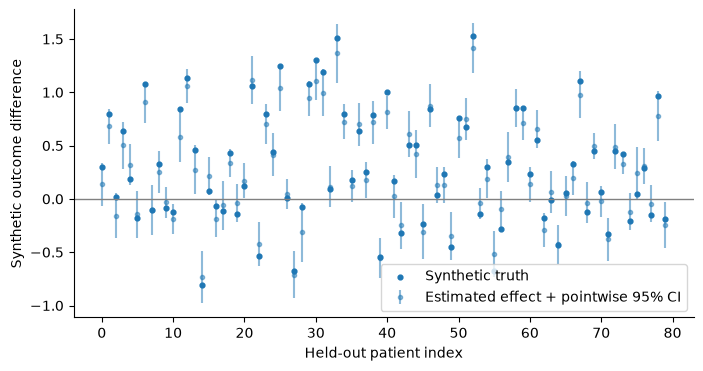

In [4]:
from plan_ml_poc.schema import REFERENCE, patient_features
from plan_ml_poc.synthetic import treatment_response

sample = test.iloc[:80]
x = patient_features(sample)
t0 = np.tile(REFERENCE, (len(sample), 1))
t1 = np.tile([1, 0.5, 4], (len(sample), 1))
effects = bundle.causal.effect(x, T0=t0, T1=t1)
ci_lower, ci_upper = bundle.causal.effect_interval(x, T0=t0, T1=t1, alpha=0.05)
truth = treatment_response(sample, t1) - treatment_response(sample, t0)
contrasts = pd.DataFrame({"effect": effects, "ci_lower": ci_lower,
                          "ci_upper": ci_upper, "simulator_truth": truth})
display(contrasts.head(10))
plt.errorbar(np.arange(len(sample)), effects, yerr=[effects-ci_lower, ci_upper-effects],
             fmt=".", alpha=0.5, label="Estimated effect + pointwise 95% CI")
plt.scatter(np.arange(len(sample)), truth, s=12, label="Synthetic truth")
plt.axhline(0, color="gray", linewidth=1)
plt.ylabel("Synthetic outcome difference")
plt.xlabel("Held-out patient index")
plt.legend()
plt.show()

The factual MAE/RMSE tests outcome prediction. Oracle effect error and fixed-contrast coverage test our invented causal world. They cannot be computed from ordinary observational clinical outcomes, where only one potential outcome is observed per patient. These are diagnostic examples, not performance promises.

Save a bundle now. Inference will load these exact fitted models, rather than retraining them for each proposed plan.

In [5]:
save_bundle(bundle, ARTIFACTS / "models")
print((ARTIFACTS / "models" / "metadata.json").read_text())

{
  "synthetic_only": true,
  "seed": 42,
  "training_rows": 2400,
  "x_columns": [
    "age",
    "bmi",
    "baseline_function",
    "preop_hka_deg",
    "mldfa_deg",
    "mpta_deg"
  ],
  "w_columns": [
    "surgeon_b",
    "hospital_b"
  ],
  "plan_columns": [
    "femoral_varus_deg",
    "tibial_varus_deg",
    "tibial_slope_deg"
  ],
  "teaching_bounds_deg": [
    [
      -3.0,
      3.0
    ],
    [
      -3.0,
      3.0
    ],
    [
      0.0,
      7.0
    ]
  ],
  "python": "3.11.12",
  "versions": {
    "econml": "0.16.0",
    "xgboost": "3.0.5",
    "scikit-learn": "1.6.1",
    "numpy": "1.26.4"
  },
  "causal_model": "LinearDML, quadratic treatment features, linear X heterogeneity",
  "warning": "Synthetic mechanics only. No clinical conclusions."
}



**Try next:** inspect `training.py`; change the treatment feature degree to 1 and compare the learned response curves. Refit before changing model structure. Do not tune repeatedly on the held-out test set and then call it untouched validation.